<a href="https://colab.research.google.com/github/bintangyudhis/Tugas-Besar-Strategi-Algoritma/blob/main/Percobaan1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install folium osmnx networkx pandas
!pip install osmnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.5/101.5 kB 4.6 MB/s eta 0:00:00


In [7]:
import pandas as pd
import folium
import osmnx as ox
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load Data

try:
    df_banjir = pd.read_csv('/content/drive/MyDrive/TugasBesar_StrategiAlgoritma/data_desa_rawan_clean.csv')
    df_evakuasi = pd.read_csv('/content/drive/MyDrive/TugasBesar_StrategiAlgoritma/tempat_evakuasi_clean.csv')
    print("✅ Data Berhasil Diload!")
except FileNotFoundError:
    print("❌ Error: File tidak ditemukan. Cek nama file atau upload ulang.")

# 2. Cek Nama Kolom (Seringkali ada spasi seperti ' Latitude' atau 'Desa ')
print("\n[INFO] Nama Kolom Asli:")
print("Banjir:", df_banjir.columns.tolist())
print("Evakuasi:", df_evakuasi.columns.tolist())

# 3. Standardisasi Nama Kolom (Menghapus spasi di awal/akhir nama kolom)
df_banjir.columns = df_banjir.columns.str.strip()
df_evakuasi.columns = df_evakuasi.columns.str.strip()

print("\n[INFO] Nama Kolom Setelah Dibersihkan:")
print("Banjir:", df_banjir.columns.tolist())
print("Evakuasi:", df_evakuasi.columns.tolist())

✅ Data Berhasil Diload!

[INFO] Nama Kolom Asli:
Banjir: ['No', 'Kecamatan', 'Desa', 'Latitude', 'Longitude']
Evakuasi: ['No', 'Nama_Tempat', 'Kecamatan', 'Latitude', 'Longitude']

[INFO] Nama Kolom Setelah Dibersihkan:
Banjir: ['No', 'Kecamatan', 'Desa', 'Latitude', 'Longitude']
Evakuasi: ['No', 'Nama_Tempat', 'Kecamatan', 'Latitude', 'Longitude']


In [11]:
# 1. Konversi ke Numerik
# errors='coerce' akan mengubah teks yang tidak bisa jadi angka menjadi NaN (kosong)
df_banjir['Latitude'] = pd.to_numeric(df_banjir['Latitude'], errors='coerce')
df_banjir['Longitude'] = pd.to_numeric(df_banjir['Longitude'], errors='coerce')

df_evakuasi['Latitude'] = pd.to_numeric(df_evakuasi['Latitude'], errors='coerce')
df_evakuasi['Longitude'] = pd.to_numeric(df_evakuasi['Longitude'], errors='coerce')

# 2. Cek Data Kosong (Null)
print(f"\nJumlah Baris Awal Banjir: {len(df_banjir)}")
print(f"Data Null di Banjir:\n{df_banjir[['Latitude', 'Longitude']].isnull().sum()}")

# 3. Buang Data yang Tidak Valid (Drop NaN)
df_banjir_clean = df_banjir.dropna(subset=['Latitude', 'Longitude'])
df_evakuasi_clean = df_evakuasi.dropna(subset=['Latitude', 'Longitude'])

print(f"\n✅ Data Siap Pakai (Banjir): {len(df_banjir_clean)} baris")
print(f"✅ Data Siap Pakai (Evakuasi): {len(df_evakuasi_clean)} baris")

# Tips: Data 'clean' inilah yang akan dipakai untuk peta dan algoritma selanjutnya.


Jumlah Baris Awal Banjir: 128
Data Null di Banjir:
Latitude     1
Longitude    1
dtype: int64

✅ Data Siap Pakai (Banjir): 127 baris
✅ Data Siap Pakai (Evakuasi): 319 baris


In [12]:
import folium

# --- 1. SETUP DATA & PUSAT PETA ---
# Kita ambil rata-rata koordinat dari data banjir sebagai titik tengah peta
center_lat = df_banjir_clean['Latitude'].mean()
center_lon = df_banjir_clean['Longitude'].mean()
center = [center_lat, center_lon]

# --- 2. MEMBUAT PETA GABUNGAN (Semua Titik) ---
m_gabungan = folium.Map(location=center, zoom_start=11, tiles='OpenStreetMap')

# Plot Titik Banjir (Merah)
for _, row in df_banjir_clean.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Banjir: {row['Desa']}",
        icon=folium.Icon(color='red', icon='exclamation-sign')
    ).add_to(m_gabungan)

# Plot Titik Evakuasi (Hijau)
for _, row in df_evakuasi_clean.iterrows():
    # Note: Kolom 'Kapasitas' tidak ada di dataset kamu, jadi saya hapus agar tidak error
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Evakuasi: {row['Nama_Tempat']}",
        icon=folium.Icon(color='green', icon='home')
    ).add_to(m_gabungan)

# Simpan Peta Gabungan
m_gabungan.save("1_Peta_Gabungan_Cilacap.html")
print("✅ Peta 1 (Gabungan) berhasil dibuat: '1_Peta_Gabungan_Cilacap.html'")


# --- 3. MEMBUAT PETA KHUSUS BANJIR (Hanya Merah) ---
m_banjir = folium.Map(location=center, zoom_start=11, tiles='OpenStreetMap')

for _, row in df_banjir_clean.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Rawan Banjir: {row['Desa']}",
        icon=folium.Icon(color='red', icon='exclamation-sign')
    ).add_to(m_banjir)

m_banjir.save("2_Peta_Khusus_Banjir.html")
print("✅ Peta 2 (Khusus Banjir) berhasil dibuat: '2_Peta_Khusus_Banjir.html'")


# --- 4. MEMBUAT PETA KHUSUS EVAKUASI (Hanya Hijau) ---
m_evakuasi = folium.Map(location=center, zoom_start=11, tiles='OpenStreetMap')

for _, row in df_evakuasi_clean.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Lokasi Evakuasi: {row['Nama_Tempat']}",
        icon=folium.Icon(color='green', icon='home')
    ).add_to(m_evakuasi)

m_evakuasi.save("3_Peta_Khusus_Evakuasi.html")
print("✅ Peta 3 (Khusus Evakuasi) berhasil dibuat: '3_Peta_Khusus_Evakuasi.html'")

m_gabungan

✅ Peta 1 (Gabungan) berhasil dibuat: '1_Peta_Gabungan_Cilacap.html'
✅ Peta 2 (Khusus Banjir) berhasil dibuat: '2_Peta_Khusus_Banjir.html'
✅ Peta 3 (Khusus Evakuasi) berhasil dibuat: '3_Peta_Khusus_Evakuasi.html'


In [13]:
# @title
import folium

# 1. Tentukan Pusat Peta (Rata-rata koordinat)
center_lat = df_banjir_clean['Latitude'].mean()
center_lon = df_banjir_clean['Longitude'].mean()

m = folium.Map(location=[center_lat, center_lon], zoom_start=11)

# 2. Plot Titik Banjir (Merah)
for idx, row in df_banjir_clean.iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=4,
        color='red',
        fill=True,
        fill_color='red',
        popup=f"Banjir: {row['Desa']}"
    ).add_to(m)

# 3. Plot Titik Evakuasi (Hijau)
for idx, row in df_evakuasi_clean.iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=f"Evakuasi: {row['Nama_Tempat']}",
        icon=folium.Icon(color='green', icon='home')
    ).add_to(m)

# 4. Tampilkan Peta
m.save("peta_cilacap_real.html")
print("✅ Peta berhasil dibuat! Buka file 'peta_cilacap_real.html' untuk melihat.")
# Jika di Google Colab, gunakan: m
m

✅ Peta berhasil dibuat! Buka file 'peta_cilacap_real.html' untuk melihat.


In [14]:
import osmnx as ox
import networkx as nx
import pandas as pd

print("⏳ Memulai proses dengan Pembersihan Data Outlier...")

# --- 1. CLEANING DATA EKSTRA (PENTING!) ---
# Kita batasi area hanya di sekitar Cilacap (Longitude 108 - 110)
# Data di luar ini dianggap salah input dan dibuang.
batas_min_lon, batas_max_lon = 108.0, 110.0
batas_min_lat, batas_max_lat = -8.0, -7.0

print(f"Data Awal Banjir: {len(df_banjir_clean)}")
print(f"Data Awal Evakuasi: {len(df_evakuasi_clean)}")

# Filter Banjir
df_banjir_clean = df_banjir_clean[
    (df_banjir_clean['Longitude'] >= batas_min_lon) &
    (df_banjir_clean['Longitude'] <= batas_max_lon) &
    (df_banjir_clean['Latitude'] >= batas_min_lat) &
    (df_banjir_clean['Latitude'] <= batas_max_lat)
]

# Filter Evakuasi
df_evakuasi_clean = df_evakuasi_clean[
    (df_evakuasi_clean['Longitude'] >= batas_min_lon) &
    (df_evakuasi_clean['Longitude'] <= batas_max_lon) &
    (df_evakuasi_clean['Latitude'] >= batas_min_lat) &
    (df_evakuasi_clean['Latitude'] <= batas_max_lat)
]

print(f"Data Bersih Banjir: {len(df_banjir_clean)}")
print(f"Data Bersih Evakuasi: {len(df_evakuasi_clean)} (Outlier dibuang)")

# --- 2. DOWNLOAD PETA (METODE PLACE) ---
# Menggunakan nama wilayah lebih aman daripada koordinat manual
print("\n🚀 Mendownload Peta Jalan Raya 'Kabupaten Cilacap'...")
try:
    # Menggunakan graph_from_place jauh lebih stabil untuk satu kabupaten
    G = ox.graph_from_place(
        "Kabupaten Cilacap, Central Java, Indonesia",
        network_type='drive'
    )
    print(f"✅ Berhasil! Total Node Jalan: {len(G.nodes)} (Harusnya ribuan)")

    # --- 3. SNAPPING (TITIK KE JALAN) ---
    print("⏳ Memetakan titik ke jalan terdekat...")

    df_banjir_clean['node_id'] = ox.distance.nearest_nodes(
        G, X=df_banjir_clean['Longitude'], Y=df_banjir_clean['Latitude']
    )

    df_evakuasi_clean['node_id'] = ox.distance.nearest_nodes(
        G, X=df_evakuasi_clean['Longitude'], Y=df_evakuasi_clean['Latitude']
    )

    print("✅ Mapping Selesai.")

    # --- 4. TES HITUNG JARAK ---
    origin = df_banjir_clean.iloc[0]['node_id'] # Desa pertama
    target = df_evakuasi_clean.iloc[0]['node_id'] # Posko pertama

    try:
        jarak = nx.shortest_path_length(G, origin, target, weight='length')
        print(f"\n[INFO SUKSES] Contoh Jarak Rute Nyata: {jarak/1000:.2f} KM")
        print("Data siap digunakan untuk algoritma Dijkstra/Tabu Search!")
    except nx.NetworkXNoPath:
        print("\n[INFO] Titik sampel tidak terhubung (beda pulau/area).")

except Exception as e:
    print(f"❌ Error Download: {e}")

⏳ Memulai proses dengan Pembersihan Data Outlier...
Data Awal Banjir: 127
Data Awal Evakuasi: 319
Data Bersih Banjir: 127
Data Bersih Evakuasi: 318 (Outlier dibuang)

🚀 Mendownload Peta Jalan Raya 'Kabupaten Cilacap'...
✅ Berhasil! Total Node Jalan: 33505 (Harusnya ribuan)
⏳ Memetakan titik ke jalan terdekat...
✅ Mapping Selesai.

[INFO SUKSES] Contoh Jarak Rute Nyata: 91.06 KM
Data siap digunakan untuk algoritma Dijkstra/Tabu Search!


In [15]:
#  EKSTRAKSI FITUR RUTE (Bahan Slide 4) ---
print("\n[INFO] Mendownload Road Network Cilacap (OSMnx)...")
try:
    # Menggunakan mode 'place' agar otomatis mendapat seluruh jalan di kabupaten
    G = ox.graph_from_place("Kabupaten Cilacap, Central Java, Indonesia", network_type='drive')
    print(f"✅ Graph Berhasil! Jumlah Node Jalan: {len(G.nodes)}")
    print(f"✅ Jumlah Edge Jalan: {len(G.edges)}")

    # SNAPPING (Menempelkan titik ke jalan)
    print("⏳ Melakukan Snapping titik ke jalan...")
    df_banjir_clean['node_id'] = ox.distance.nearest_nodes(G, df_banjir_clean['Longitude'], df_banjir_clean['Latitude'])
    df_evakuasi_clean['node_id'] = ox.distance.nearest_nodes(G, df_evakuasi_clean['Longitude'], df_evakuasi_clean['Latitude'])

    # CONTOH PERHITUNGAN JARAK NYATA
    origin = df_banjir_clean.iloc[0]['node_id']
    target = df_evakuasi_clean.iloc[0]['node_id']

    # Hitung jarak terpendek via jalan raya
    jarak_meter = nx.shortest_path_length(G, origin, target, weight='length')

    print("\n[HASIL EKSTRAKSI FITUR]")
    print(f"Sampel Desa: {df_banjir_clean.iloc[0]['Desa']}")
    print(f"Sampel Evakuasi: {df_evakuasi_clean.iloc[0]['Nama_Tempat']}")
    print(f"Jarak Jalan Raya (Real): {jarak_meter/1000:.2f} KM")

except Exception as e:
    print(f"❌ Error OSMnx: {e}")


[INFO] Mendownload Road Network Cilacap (OSMnx)...
✅ Graph Berhasil! Jumlah Node Jalan: 33505
✅ Jumlah Edge Jalan: 81995
⏳ Melakukan Snapping titik ke jalan...

[HASIL EKSTRAKSI FITUR]
Sampel Desa: Desa Panulisan Barat 
Sampel Evakuasi: SMP N 1 Cilacap
Jarak Jalan Raya (Real): 91.06 KM


In [16]:
import folium
import networkx as nx
import osmnx as ox

# --- KONFIGURASI ---
# Ambil satu sampel desa untuk demo (misal data pertama)
# Pastikan nama variabel sesuai dengan yang ada di memori Anda
sampel_banjir = df_banjir_clean.iloc[15]

print(f"📍 Membuat visualisasi rute untuk: {sampel_banjir['Desa']}...")

# --- 1. HITUNG RUTE TERDEKAT (DI MEMORI) ---
origin_node = sampel_banjir['node_id']

shortest_dist = float('inf')
best_route = None
best_evakuasi = None

# Cek 50 titik evakuasi pertama saja untuk demo cepat
print("⏳ Mencari posko terdekat via jalan raya...")
for idx, row in df_evakuasi_clean.head(50).iterrows():
    target_node = row['node_id']
    try:
        # Hitung jarak
        dist = nx.shortest_path_length(G, origin_node, target_node, weight='length')
        if dist < shortest_dist:
            shortest_dist = dist
            best_evakuasi = row
            # Ambil detail rutenya (list of nodes)
            best_route = nx.shortest_path(G, origin_node, target_node, weight='length')
    except nx.NetworkXNoPath:
        continue

if best_evakuasi is None:
    print("❌ Tidak ditemukan rute (mungkin terpisah sungai/pulau). Coba sampel desa lain.")
else:
    print(f"✅ Rute Ditemukan!")
    print(f"   Tujuan: {best_evakuasi['Nama_Tempat']}")
    print(f"   Jarak: {shortest_dist/1000:.2f} KM")

    # --- 2. GAMBAR PETA (FOLIUM) ---
    # Pusat peta
    center = [sampel_banjir['Latitude'], sampel_banjir['Longitude']]
    m_rute = folium.Map(location=center, zoom_start=13, tiles='OpenStreetMap')

    # A. Titik Banjir (Merah)
    folium.Marker(
        [sampel_banjir['Latitude'], sampel_banjir['Longitude']],
        popup=f"<b>START: {sampel_banjir['Desa']}</b>",
        icon=folium.Icon(color='red', icon='exclamation-circle', prefix='fa')
    ).add_to(m_rute)

    # B. Titik Evakuasi Tujuan (Biru/Hijau)
    folium.Marker(
        [best_evakuasi['Latitude'], best_evakuasi['Longitude']],
        popup=f"<b>FINISH: {best_evakuasi['Nama_Tempat']}</b><br>Jarak: {shortest_dist/1000:.2f} KM",
        icon=folium.Icon(color='blue', icon='flag', prefix='fa')
    ).add_to(m_rute)

    # C. Garis Rute (Polyline)
    if best_route:
        # Ambil koordinat lat,lon dari node rute
        route_coords = []
        for node in best_route:
            # Di OSMnx v2, akses atribut node pakai G.nodes[node]
            point = G.nodes[node]
            route_coords.append([point['y'], point['x']]) # Folium butuh [Lat, Lon]

        folium.PolyLine(
            route_coords,
            color="blue",
            weight=5,
            opacity=0.7,
            tooltip=f"Jarak Tempuh: {shortest_dist/1000:.2f} KM"
        ).add_to(m_rute)

    # Simpan dan Tampilkan
    m_rute.save("Peta_Progres1_Rute.html")
    print("\n✅ Peta siap! Buka file 'Peta_Progres1_Rute.html'")

    # Jika di Jupyter, tampilkan:
    m_rute

📍 Membuat visualisasi rute untuk: Desa Bener...
⏳ Mencari posko terdekat via jalan raya...
✅ Rute Ditemukan!
   Tujuan: Balai Desa Panulisan Timur
   Jarak: 27.35 KM

✅ Peta siap! Buka file 'Peta_Progres1_Rute.html'


In [17]:
# Pastikan kode sebelumnya sudah dijalankan dan variabel 'm_rute' sudah ada
from IPython.display import display

# Perintah ini akan memunculkan peta interaktif langsung di sini
display(m_rute)



📸 Sedang memotret struktur jaringan jalan (Graph Structure)...
✅ Gambar tersimpan: 'images/graph_shape.png' (atau cek folder default)


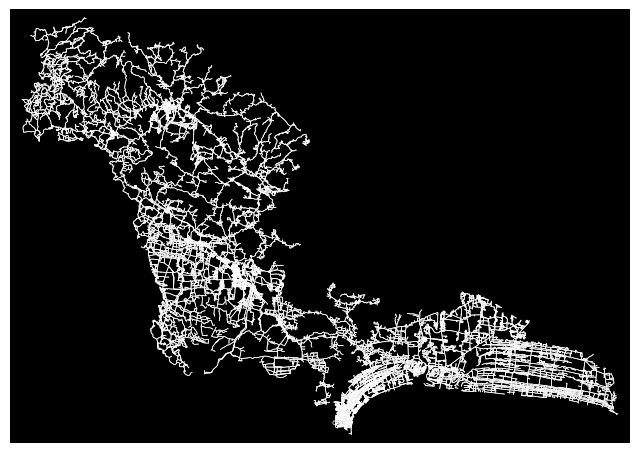

📸 Sedang memotret seluruh jaringan jalan (Graph)...


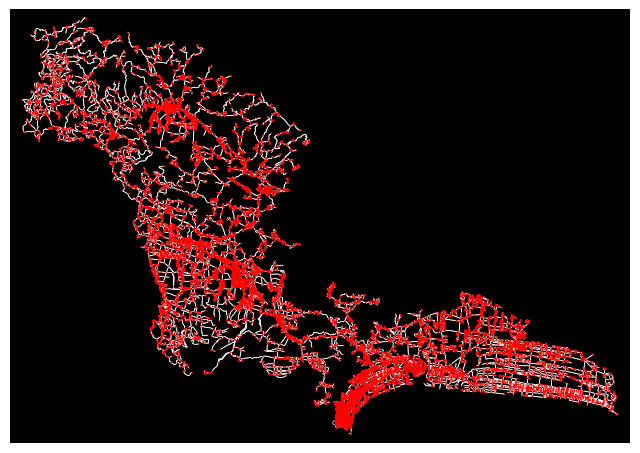

✅ Gambar di atas adalah visualisasi Node & Edge jalan raya yang akan dihitung algoritma.


In [18]:
import matplotlib.pyplot as plt
import osmnx as ox
import matplotlib.pyplot as plt

print("📸 Sedang memotret struktur jaringan jalan (Graph Structure)...")

# Pastikan variabel G sudah ada (dari proses sebelumnya)
# plot_graph menghasilkan gambar statis titik (node) dan garis (edge)
fig, ax = ox.plot_graph(
    G,
    node_size=0,          # Nolkan node biar tidak terlalu semrawut (fokus ke jalan)
    edge_color='w',       # Warna jalan putih
    edge_linewidth=0.5,   # Ketebalan garis
    bgcolor='k',          # Background hitam (terlihat profesional untuk PPT)
    show=False,
    close=False,
    filepath='Struktur_Jalan_Cilacap.png',
    save=True
)

print("✅ Gambar tersimpan: 'images/graph_shape.png' (atau cek folder default)")
plt.show()

print("📸 Sedang memotret seluruh jaringan jalan (Graph)...")

# Fungsi ini menggambar RAW data: Node (Titik) dan Edge (Garis Jalan)
fig, ax = ox.plot_graph(
    G,
    node_size=1,            # Ukuran titik node (kecil saja biar rapi)
    node_color='red',       # Warna titik merah
    edge_color='white',     # Warna jalan putih
    edge_linewidth=0.5,     # Ketebalan jalan
    bgcolor='black',        # Latar belakang hitam
    show=True               # Tampilkan gambar
)

print("✅ Gambar di atas adalah visualisasi Node & Edge jalan raya yang akan dihitung algoritma.")

In [20]:
import folium
import networkx as nx
import osmnx as ox
from folium.features import DivIcon

print("🚀 Memulai perhitungan dan visualisasi...")

# --- 1. DEFINISI ULANG VARIABEL (Agar tidak NameError) ---
# Ambil sampel desa pertama
sampel_banjir = df_banjir_clean.iloc[15]
origin_node = sampel_banjir['node_id']

print(f"📍 Mencari rute dari: {sampel_banjir['Desa']}...")

# Reset variabel penampung
shortest_dist = float('inf')
best_route = None
best_evakuasi = None

# --- 2. LOGIKA PENCARIAN RUTE TERDEKAT ---
# Kita cek 50 titik evakuasi pertama untuk mencari yang paling dekat via jalan raya
for idx, row in df_evakuasi_clean.head(50).iterrows():
    target_node = row['node_id']
    try:
        dist = nx.shortest_path_length(G, origin_node, target_node, weight='length')
        if dist < shortest_dist:
            shortest_dist = dist
            best_evakuasi = row
            # Simpan rute (daftar node yang dilewati)
            best_route = nx.shortest_path(G, origin_node, target_node, weight='length')
    except nx.NetworkXNoPath:
        continue

if best_evakuasi is None:
    print("❌ Rute tidak ditemukan. Coba ganti sampel desa.")
else:
    print(f"✅ Rute Ditemukan!")
    print(f"   Tujuan: {best_evakuasi['Nama_Tempat']}")
    print(f"   Jarak: {shortest_dist/1000:.2f} KM")

    # --- 3. VISUALISASI PETA DETAIL ---
    # Titik tengah antara Start dan Finish untuk pusat peta
    center_lat = (sampel_banjir['Latitude'] + best_evakuasi['Latitude']) / 2
    center_lon = (sampel_banjir['Longitude'] + best_evakuasi['Longitude']) / 2

    m_detail = folium.Map(location=[center_lat, center_lon], zoom_start=14, tiles='OpenStreetMap')

    # A. Gambar Garis Rute (Biru Tebal)
    route_coords = []
    for node in best_route:
        # Mengambil koordinat (y=lat, x=lon) dari setiap node jalan
        point = G.nodes[node]
        route_coords.append([point['y'], point['x']])

    folium.PolyLine(
        route_coords,
        color="blue",
        weight=6,
        opacity=0.6,
        tooltip=f"Jarak: {shortest_dist/1000:.2f} KM"
    ).add_to(m_detail)

    # B. Gambar Node Putih (Titik-titik di sepanjang garis biru)
    # Ini visualisasi simpul graph-nya
    for node in best_route:
        point = G.nodes[node]
        folium.CircleMarker(
            location=[point['y'], point['x']],
            radius=2,
            color='white',
            fill=True,
            fill_color='blue',
            fill_opacity=1
        ).add_to(m_detail)

    # C. Marker Start (Merah) & Finish (Hijau)
    folium.Marker(
        [sampel_banjir['Latitude'], sampel_banjir['Longitude']],
        popup=f"<b>START: {sampel_banjir['Desa']}</b>",
        icon=folium.Icon(color='red', icon='exclamation-circle', prefix='fa')
    ).add_to(m_detail)

    folium.Marker(
        [best_evakuasi['Latitude'], best_evakuasi['Longitude']],
        popup=f"<b>FINISH: {best_evakuasi['Nama_Tempat']}</b>",
        icon=folium.Icon(color='green', icon='flag', prefix='fa')
    ).add_to(m_detail)

    # D. Label Teks Jarak (Melayang di Tengah Peta)
    mid_point = route_coords[len(route_coords)//2] # Ambil titik tengah rute

    folium.map.Marker(
        mid_point,
        icon=DivIcon(
            icon_size=(150,36),
            icon_anchor=(75,18),
            html=f"""<div style="
                font-size: 10pt;
                font-weight: bold;
                color: black;
                background-color: white;
                border: 2px solid blue;
                border-radius: 5px;
                padding: 2px;
                text-align: center;">
                Jarak: {shortest_dist/1000:.2f} KM
                </div>"""
            )
        ).add_to(m_detail)

    # Tampilkan Peta Langsung
    from IPython.display import display
    display(m_detail)

    # Simpan file juga (backup)
    m_detail.save("Peta_Progres1_Final.html")
    print("\n✅ Peta berhasil dibuat! Jika tidak muncul di atas, download file 'Peta_Progres1_Final.html'")

🚀 Memulai perhitungan dan visualisasi...
📍 Mencari rute dari: Desa Bener...
✅ Rute Ditemukan!
   Tujuan: Balai Desa Panulisan Timur
   Jarak: 27.35 KM



✅ Peta berhasil dibuat! Jika tidak muncul di atas, download file 'Peta_Progres1_Final.html'
